In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)

In [ ]:

heads = np.array([5, 9, 8, 4, 7], dtype=float)


tails = 10 - heads

data = pd.DataFrame({
    "Sequence": [1, 2, 3, 4, 5],
    "Heads": heads.astype(int),
    "Tails": tails.astype(int)
})

display(data)
print("Total Heads:", int(heads.sum()))
print("Total Tails:", int(tails.sum()))

,Sequence,Heads,Tails
0,1,5,5
1,2,9,1
2,3,8,2
3,4,4,6
4,5,7,3


Total Heads: 33
Total Tails: 17


In [3]:
theta_A = 0.60
theta_B = 0.50

pi_A = 0.50
pi_B = 0.50

number_of_sequences = len(heads)
tosses_per_sequence = 10

print("Initial theta A:", theta_A)
print("Initial theta B:", theta_B)
print("Initial pi A:", pi_A)
print("Initial pi B:", pi_B)

Initial theta A: 0.6
Initial theta B: 0.5
Initial pi A: 0.5
Initial pi B: 0.5


In [4]:
history = []
responsibility_history = []

for iteration in range(1, 11):

    # ---------------- E-STEP ----------------
    log_A = (
        np.log(pi_A)
        + heads * np.log(theta_A)
        + tails * np.log1p(-theta_A)
    )

    log_B = (
        np.log(pi_B)
        + heads * np.log(theta_B)
        + tails * np.log1p(-theta_B)
    )

    # Stable calculation of P(A | sequence)
    maximum = np.maximum(log_A, log_B)
    log_denominator = maximum + np.log(
        np.exp(log_A - maximum) + np.exp(log_B - maximum)
    )

    responsibility_A = np.exp(log_A - log_denominator)
    responsibility_B = 1 - responsibility_A

    responsibility_history.append(
        [responsibility_A.copy(), responsibility_B.copy()]
    )

    # ---------------- M-STEP ----------------
    N_A = responsibility_A.sum()
    N_B = responsibility_B.sum()

    new_theta_A = np.sum(responsibility_A * heads) / (
        tosses_per_sequence * N_A
    )
    new_theta_B = np.sum(responsibility_B * heads) / (
        tosses_per_sequence * N_B
    )

    new_pi_A = N_A / number_of_sequences
    new_pi_B = N_B / number_of_sequences

    # Observed-data log-likelihood after the M-step
    new_log_A = (
        np.log(new_pi_A)
        + heads * np.log(new_theta_A)
        + tails * np.log1p(-new_theta_A)
    )

    new_log_B = (
        np.log(new_pi_B)
        + heads * np.log(new_theta_B)
        + tails * np.log1p(-new_theta_B)
    )

    max_new = np.maximum(new_log_A, new_log_B)
    log_likelihood = np.sum(
        max_new + np.log(
            np.exp(new_log_A - max_new)
            + np.exp(new_log_B - max_new)
        )
    )

    history.append({
        "Iteration": iteration,
        "Theta A": new_theta_A,
        "Theta B": new_theta_B,
        "Pi A": new_pi_A,
        "Pi B": new_pi_B,
        "Log-likelihood": log_likelihood
    })

    # Update parameters for the next iteration
    theta_A = new_theta_A
    theta_B = new_theta_B
    pi_A = new_pi_A
    pi_B = new_pi_B

result = pd.DataFrame(history)
result["Change in log-likelihood"] = result["Log-likelihood"].diff()

display(result.round(6))

,Iteration,Theta A,Theta B,Pi A,Pi B,Log-likelihood,Change in log-likelihood
0,1,0.713012,0.581339,0.597395,0.402605,-31.850656,NaN
1,2,0.732745,0.554938,0.590876,0.409124,-31.735264,0.115391
2,3,0.752230,0.531561,0.582044,0.417956,-31.642315,0.092949
3,4,0.767422,0.516160,0.572471,0.427529,-31.595322,0.046994
4,5,0.777115,0.508721,0.563646,0.436354,-31.578747,0.016574
5,6,0.782678,0.506276,0.556161,0.443839,-31.573504,0.005243
6,7,0.785850,0.506175,0.550013,0.449987,-31.571504,0.001999
7,8,0.787770,0.506951,0.545011,0.454989,-31.570488,0.001016
8,9,0.789034,0.507948,0.540945,0.459055,-31.569875,0.000613
9,10,0.789933,0.508914,0.537636,0.462364,-31.569480,0.000395


In [5]:
responsibility_rows = []

for iteration, (rA, rB) in enumerate(responsibility_history, start=1):
    for seq in range(number_of_sequences):
        responsibility_rows.append({
            "Iteration": iteration,
            "Sequence": seq + 1,
            "P(A | sequence)": rA[seq],
            "P(B | sequence)": rB[seq]
        })

responsibility_table = pd.DataFrame(responsibility_rows)
display(responsibility_table.round(6))

,Iteration,Sequence,P(A | sequence),P(B | sequence)
0,1,1,0.449149,0.550851
1,1,2,0.804986,0.195014
2,1,3,0.733467,0.266533
3,1,4,0.352156,0.647844
4,1,5,0.647215,0.352785
5,2,1,0.383986,0.616014
6,2,2,0.864652,0.135348
7,2,3,0.781203,0.218797
8,2,4,0.258371,0.741629
9,2,5,0.666168,0.333832


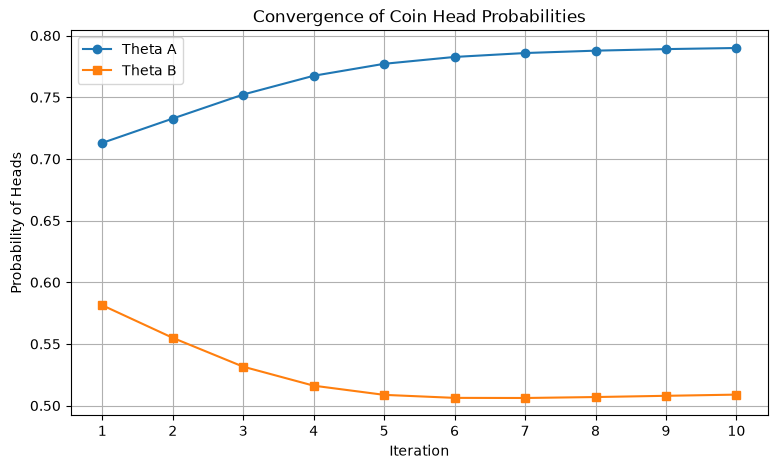

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(result["Iteration"], result["Theta A"], marker="o", label="Theta A")
plt.plot(result["Iteration"], result["Theta B"], marker="s", label="Theta B")
plt.xlabel("Iteration")
plt.ylabel("Probability of Heads")
plt.title("Convergence of Coin Head Probabilities")
plt.xticks(range(1, 11))
plt.grid(True)
plt.legend()
plt.show()

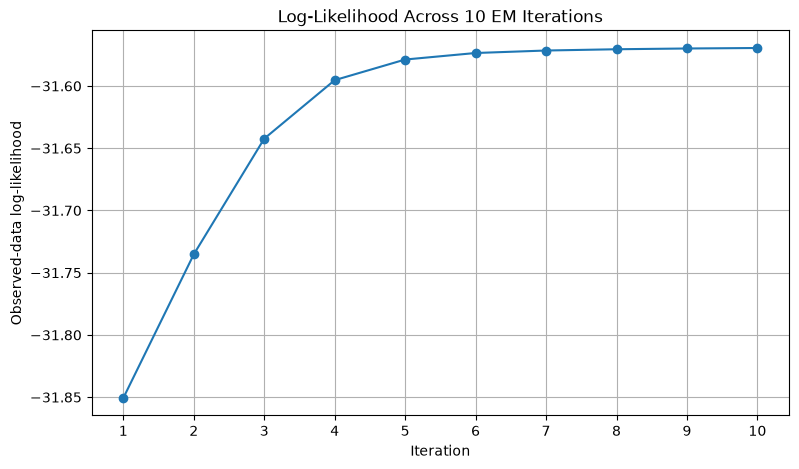

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(
    result["Iteration"],
    result["Log-likelihood"],
    marker="o"
)
plt.xlabel("Iteration")
plt.ylabel("Observed-data log-likelihood")
plt.title("Log-Likelihood Across 10 EM Iterations")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

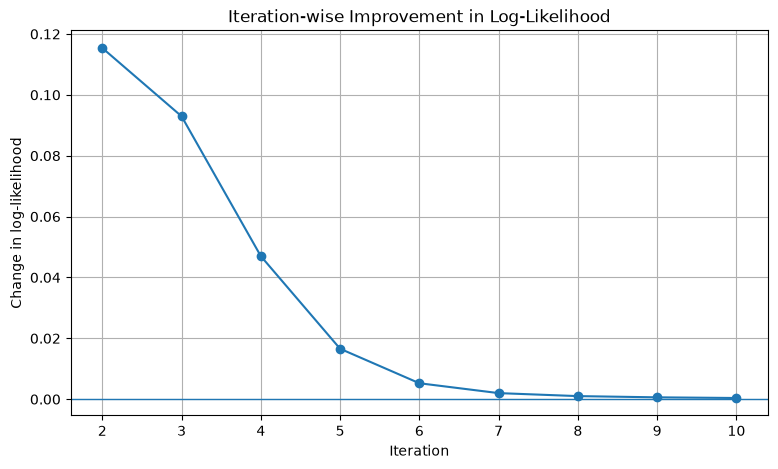

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(
    result["Iteration"].iloc[1:],
    result["Change in log-likelihood"].iloc[1:],
    marker="o"
)
plt.axhline(0, linewidth=1)
plt.xlabel("Iteration")
plt.ylabel("Change in log-likelihood")
plt.title("Iteration-wise Improvement in Log-Likelihood")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [9]:
comparison = result[[
    "Iteration",
    "Theta A",
    "Theta B",
    "Pi A",
    "Pi B",
    "Log-likelihood",
    "Change in log-likelihood"
]].copy()

display(comparison.round(8))

,Iteration,Theta A,Theta B,Pi A,Pi B,Log-likelihood,Change in log-likelihood
0,1,0.713012,0.581339,0.597395,0.402605,-31.850656,NaN
1,2,0.732745,0.554938,0.590876,0.409124,-31.735264,0.115391
2,3,0.752230,0.531561,0.582044,0.417956,-31.642315,0.092949
3,4,0.767422,0.516160,0.572471,0.427529,-31.595322,0.046994
4,5,0.777115,0.508721,0.563646,0.436354,-31.578747,0.016574
5,6,0.782678,0.506276,0.556161,0.443839,-31.573504,0.005243
6,7,0.785850,0.506175,0.550013,0.449987,-31.571504,0.001999
7,8,0.787770,0.506951,0.545011,0.454989,-31.570488,0.001016
8,9,0.789034,0.507948,0.540945,0.459055,-31.569875,0.000613
9,10,0.789933,0.508914,0.537636,0.462364,-31.569480,0.000395
